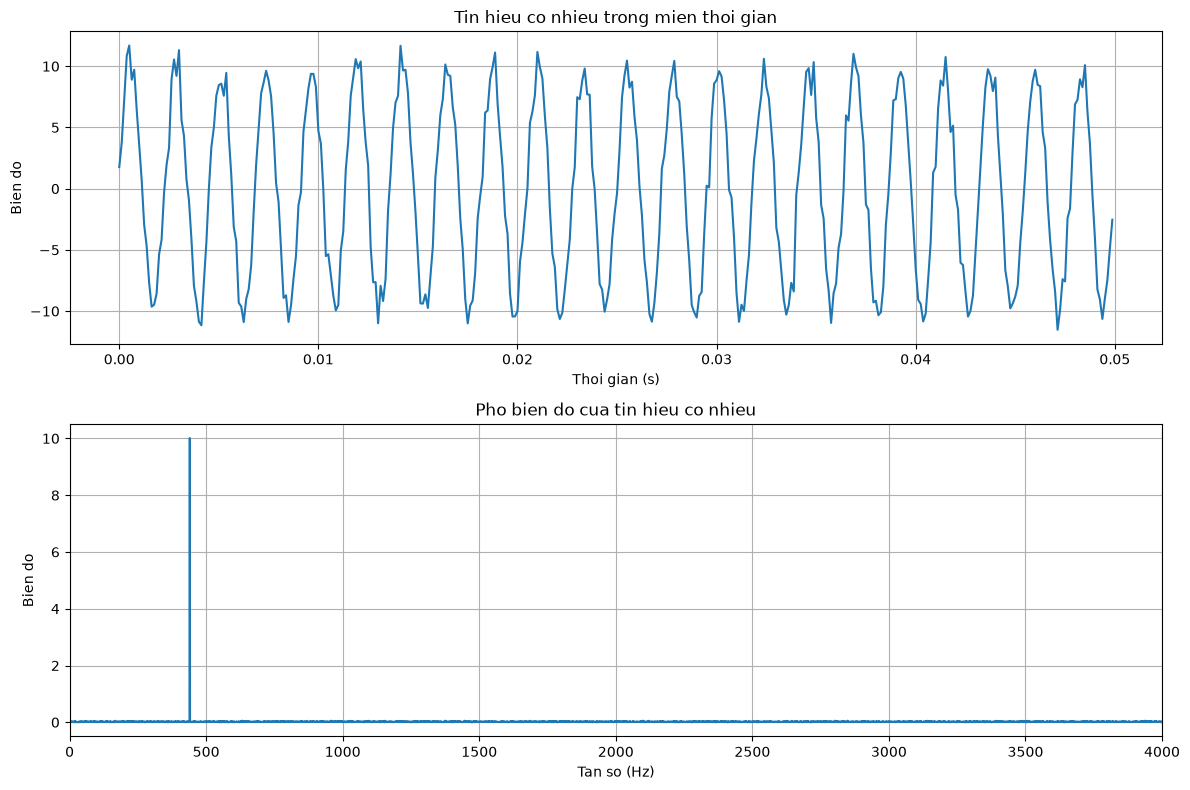

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Thiet lap thong so
fs = 8000
T = 1
t = np.arange(0, T, 1/fs)
f0 = 440

# 2. Tao tin hieu sin
x = 10 * np.sin(2 * np.pi * f0 * t)

# 3. Tao nhieu trang Gaussian
np.random.seed(0)
noise = np.random.randn(len(t))

# 4. Cong nhieu vao tin hieu
xn = x + noise

# 5. Pho bien do trong mien tan so
N = len(xn)
X = np.fft.rfft(xn)
f = np.fft.rfftfreq(N, 1/fs)
magnitude = np.abs(X) / N * 2

# 6. Ve do thi
plt.figure(figsize=(12, 8))

# Tin hieu trong mien thoi gian
plt.subplot(2, 1, 1)
plt.plot(t[:400], xn[:400])
plt.title("Tin hieu co nhieu trong mien thoi gian")
plt.xlabel("Thoi gian (s)")
plt.ylabel("Bien do")
plt.grid(True)

# Tin hieu trong mien tan so
plt.subplot(2, 1, 2)
plt.plot(f, magnitude)
plt.title("Pho bien do cua tin hieu co nhieu")
plt.xlabel("Tan so (Hz)")
plt.ylabel("Bien do")
plt.xlim(0, fs/2)
plt.grid(True)

plt.tight_layout()
plt.show()


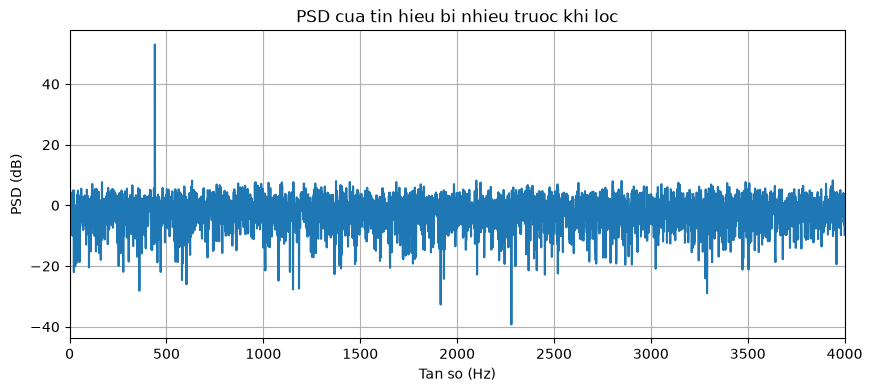

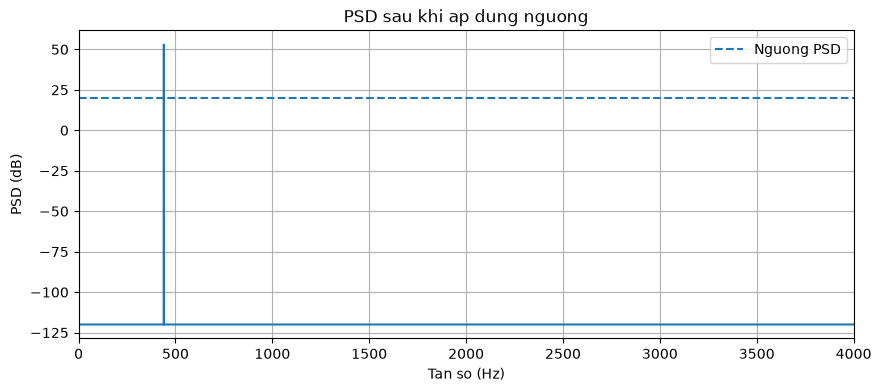

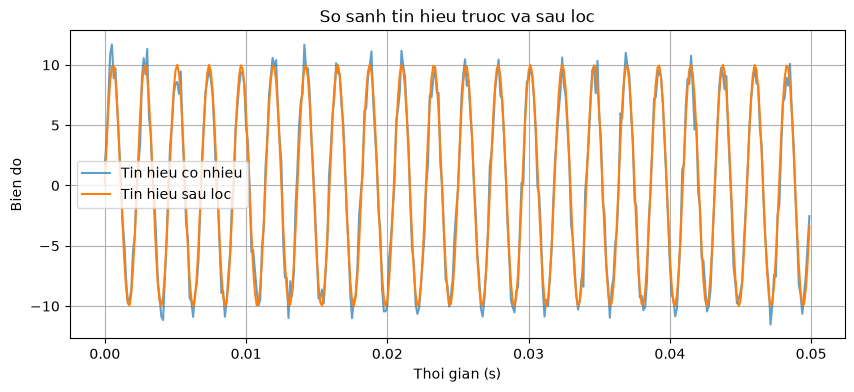

In [3]:

# 1. Tinh FFT cua tin hieu bi nhieu
N = len(xn)
Xn = np.fft.rfft(xn)
f = np.fft.rfftfreq(N, d=1/fs)

# 2. Tinh PSD
PSD = np.abs(Xn)**2 / N

# 3. Ve PSD truoc khi loc
PSD_dB = 10 * np.log10(PSD + 1e-12)

plt.figure(figsize=(10, 4))
plt.plot(f, PSD_dB)
plt.title("PSD cua tin hieu bi nhieu truoc khi loc")
plt.xlabel("Tan so (Hz)")
plt.ylabel("PSD (dB)")
plt.xlim(0, fs/2)
plt.grid(True)
plt.show()

# 4. Chon nguong PSD
threshold = 100

# 5. Ap dung nguong
PSD_filtered = np.where(PSD >= threshold, PSD, 0)

# 6. Tao mat na tan so va loc pho FFT
mask = PSD >= threshold
X_filtered = Xn * mask

# 7. Khoi phuc tin hieu bang IFFT
xn_filtered = np.fft.irfft(X_filtered, n=N)

# 8. Ve PSD sau khi loc
PSD_filtered_dB = 10 * np.log10(PSD_filtered + 1e-12)

plt.figure(figsize=(10, 4))
plt.plot(f, PSD_filtered_dB)
plt.axhline(10*np.log10(threshold), linestyle="--",
            label="Nguong PSD")
plt.title("PSD sau khi ap dung nguong")
plt.xlabel("Tan so (Hz)")
plt.ylabel("PSD (dB)")
plt.xlim(0, fs/2)
plt.legend()
plt.grid(True)
plt.show()

# 9. So sanh tin hieu truoc va sau loc
plt.figure(figsize=(10, 4))
plt.plot(t[:400], xn[:400], label="Tin hieu co nhieu", alpha=0.7)
plt.plot(t[:400], xn_filtered[:400], label="Tin hieu sau loc")
plt.xlabel("Thoi gian (s)")
plt.ylabel("Bien do")
plt.title("So sanh tin hieu truoc va sau loc")
plt.legend()
plt.grid(True)
plt.show()
